# Lecture 7 — Part-to-Whole: Colour Vision Deficiency, Treemaps & Stacked Bars

> **Dataset:** Global Energy Mix — energy sources by country (based on the structure of [Our World in Data](https://ourworldindata.org/)'s global energy dataset)

> **Source of figures:** Knaflic, C. N. (2015). *Storytelling with data*. Wiley

---
## Opening: Model Answer Review 

---
## Design Principles - Part II: Colour Vision Deficiency (CVD) 🎨

### What is CVD?

Roughly **8% of men and 0.5% of women** have some form of colour vision deficiency. In a lecture hall of 60 people, expect 2–3 people who cannot reliably tell your red bar from your green one

| Type | Affected cones | Prevalence (men) | What gets confused |
|---|---|---|---|
| Deuteranomaly / Deuteranopia | Green (M) | ~6% | Red ↔ green, brown ↔ olive |
| Protanomaly / Protanopia | Red (L) | ~2% | Red ↔ green, red looks dark |
| Tritanomaly / Tritanopia | Blue (S) | < 0.01% | Blue ↔ green, yellow ↔ pink |
| Monochromacy | All / none | very rare | Sees lightness only |


[color blindness simulator](https://www.color-blindness.com/coblis-color-blindness-simulator/)

### Designing for CVD

**💡 Five rules:**
- **Never let hue alone carry the meaning** — back it up with a direct label, position or lightness difference
- **Avoid red + green as the only differentiator** — use blue + orange or blue + red instead (safe for all common CVD types)
- **Vary lightness, not just hue** — a dark and a light colour stay distinguishable even in greyscale
- **Single-hue sequential scales for ordered data** — `Blues`, `Viridis`, `Cividis`; never rainbow
- **Grey + one accent** — the SWD default is CVD-friendly almost by construction: only one hue has to be recognised

> 💡 **Our course palette is CVD-safe:** blue `#2E75B6`, orange `#E07B39`, yellow `#F5C842`, grey `#AAAAAA` — the blue/orange pair carries the contrast, yellow is separated by lightness, grey is context.

### Where to find CVD-safe palettes

**Built into Plotly** (`px.colors`)
- Qualitative: `px.colors.qualitative.Safe` (designed to be colour-blind safe)
- Sequential: `Cividis`, `Viridis`, `Blues`, `Oranges`
- Diverging: `px.colors.diverging.BrBG`, `PuOr`, `RdBu` 

**Curated palettes**

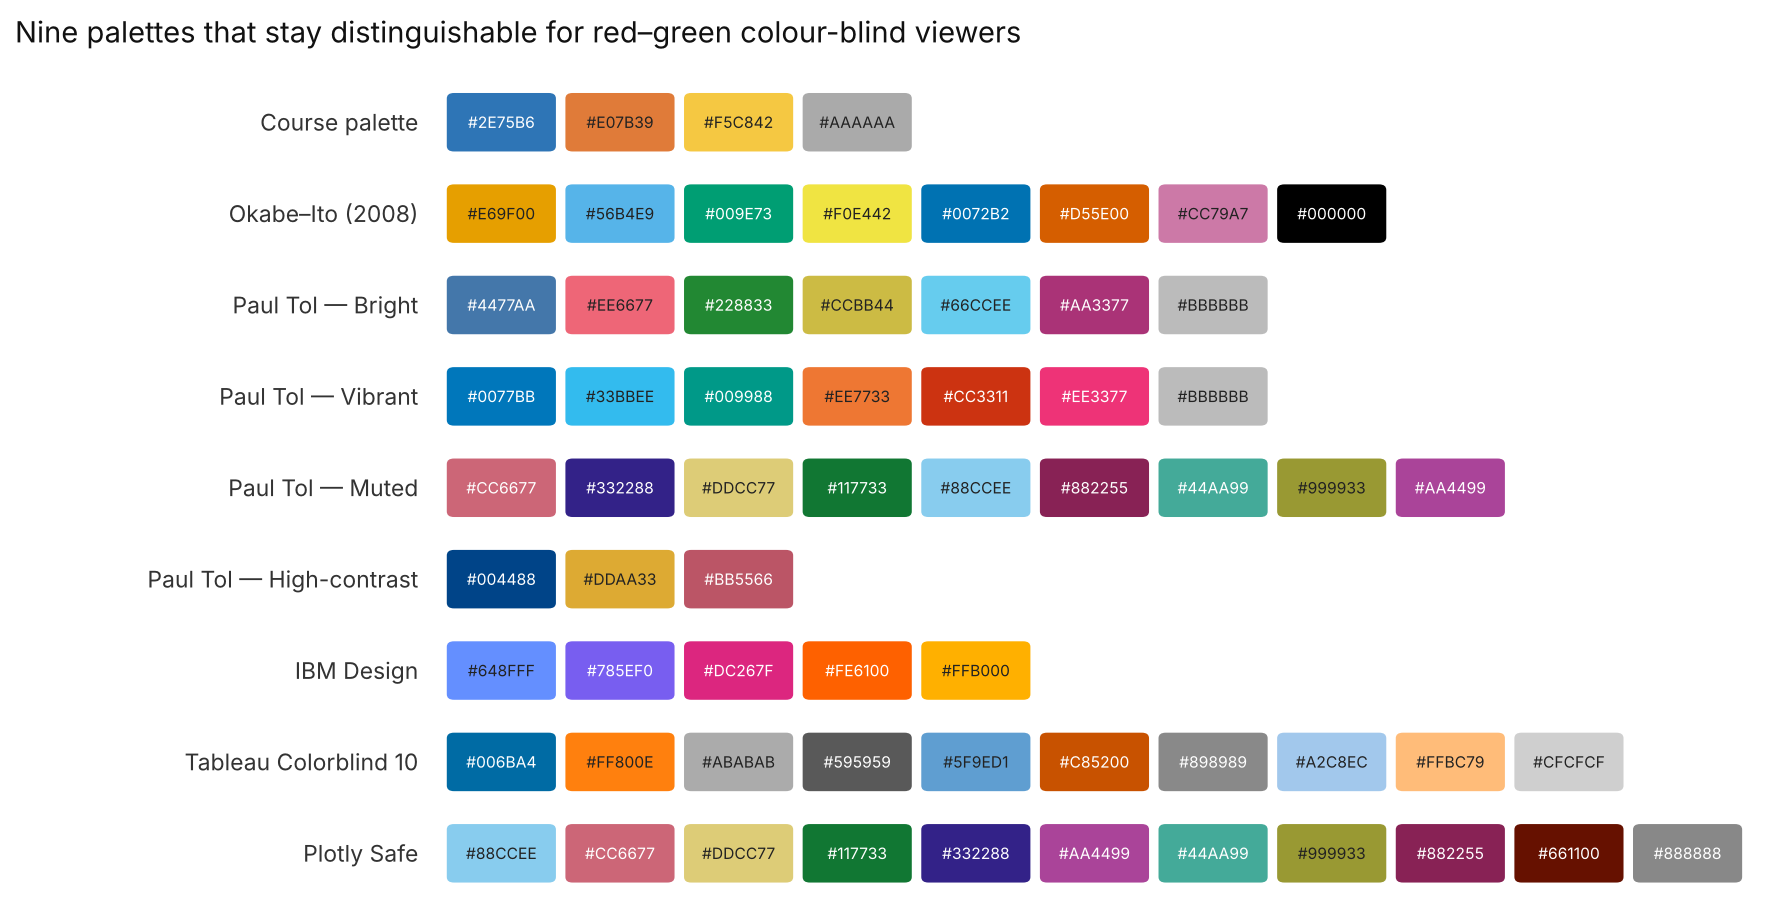

| Palette | Hex codes |
|---|---|
| Course palette | `["#2E75B6", "#E07B39", "#F5C842", "#AAAAAA"]` |
| Okabe–Ito (2008) | `["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#000000"]` |
| Paul Tol — Bright | `["#4477AA", "#EE6677", "#228833", "#CCBB44", "#66CCEE", "#AA3377", "#BBBBBB"]` |
| Paul Tol — Vibrant | `["#0077BB", "#33BBEE", "#009988", "#EE7733", "#CC3311", "#EE3377", "#BBBBBB"]` |
| Paul Tol — Muted | `["#CC6677", "#332288", "#DDCC77", "#117733", "#88CCEE", "#882255", "#44AA99", "#999933", "#AA4499"]` |
| Paul Tol — High-contrast | `["#004488", "#DDAA33", "#BB5566"]` |
| IBM Design | `["#648FFF", "#785EF0", "#DC267F", "#FE6100", "#FFB000"]` |
| Tableau Colorblind 10 | `["#006BA4", "#FF800E", "#ABABAB", "#595959", "#5F9ED1", "#C85200", "#898989", "#A2C8EC", "#FFBC79", "#CFCFCF"]` |
| Plotly Safe | `["#88CCEE", "#CC6677", "#DDCC77", "#117733", "#332288", "#AA4499", "#44AA99", "#999933", "#882255", "#661100", "#888888"]` |

---
## Design Principles - Part II: Part-to-Whole


### Visualizing Hierarchical Data

> 💡 **When the data has hierarchy — categories that contain sub-categories, such as region → country → energy source — we have two good options: a stacked bar chart or a treemap. They show the same data but answer different questions, so the choice depends on what you want the reader to see.**

**💡 Use a stacked bar chart when:**
- The story is the *composition*, compared across groups — e.g. "whose energy mix is most fossil-heavy?"
- Each bar is split into only a **few sub-categories (roughly 2–5 segments)** 
- Precise comparison matters — bars share a common baseline, and length is easier to judge than area
- You want to rank groups by one part of the whole — sort by the segment that matters and place it on the baseline
- You have only one level of hierarchy
- Use **100% stacked** bars when the *mix* is the story, and **absolute** stacked bars when the *total* matters too


*100% stacked bars — the bar alternative to pie for part-to-whole [ FIGURE 6.3 — p.156 ]*
> 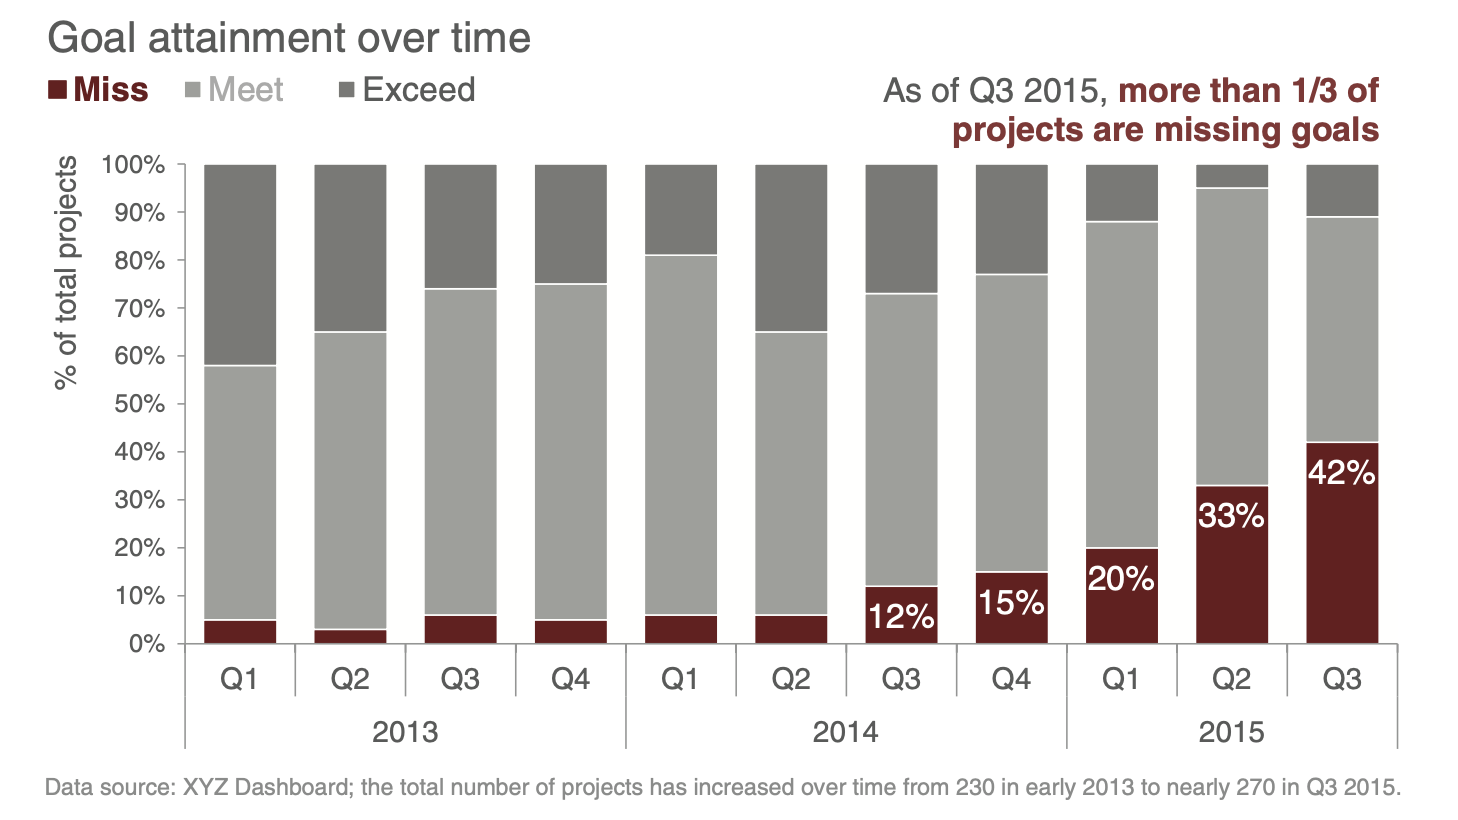 

*Horizontal stacked bars with three priority levels in shades of one colour [ FIGURE 6.5 — p.161 ]*
> 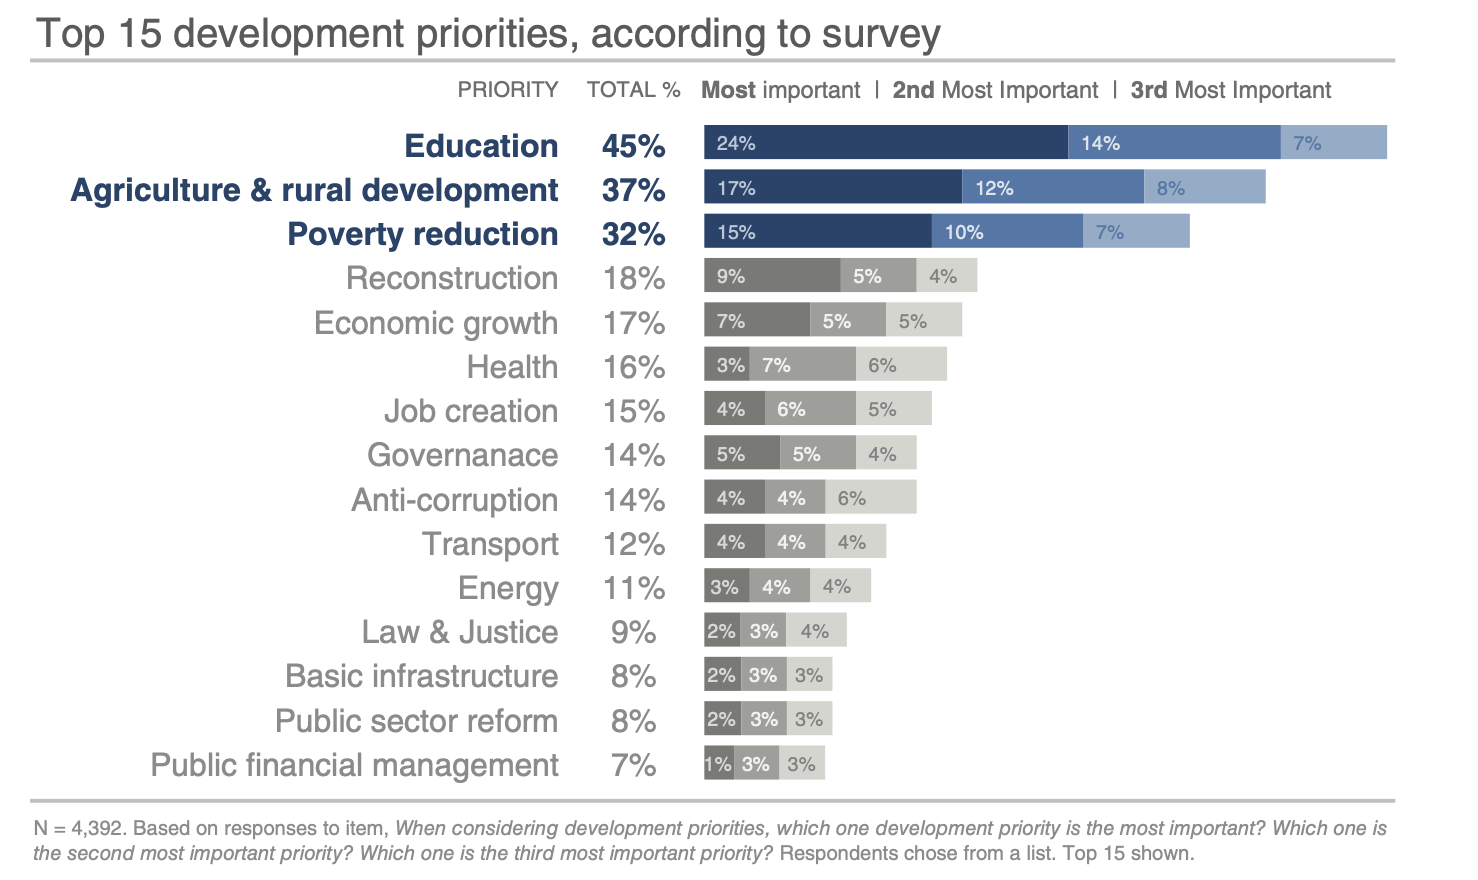 


**💡 Use a treemap when:**
- The story is *magnitude within a hierarchy* — e.g. "where is the energy consumed, and how is each part made up?"
- There are **many sub-categories** — each one simply becomes a smaller rectangle, so the chart stays readable where a stacked bar would fragment
- The nesting itself matters — a treemap shows region → country → source in one view
- An overview of relative size matters more than exact values or ranking
- Colour can encode a second variable, such as source type or renewable share, on top of size

> 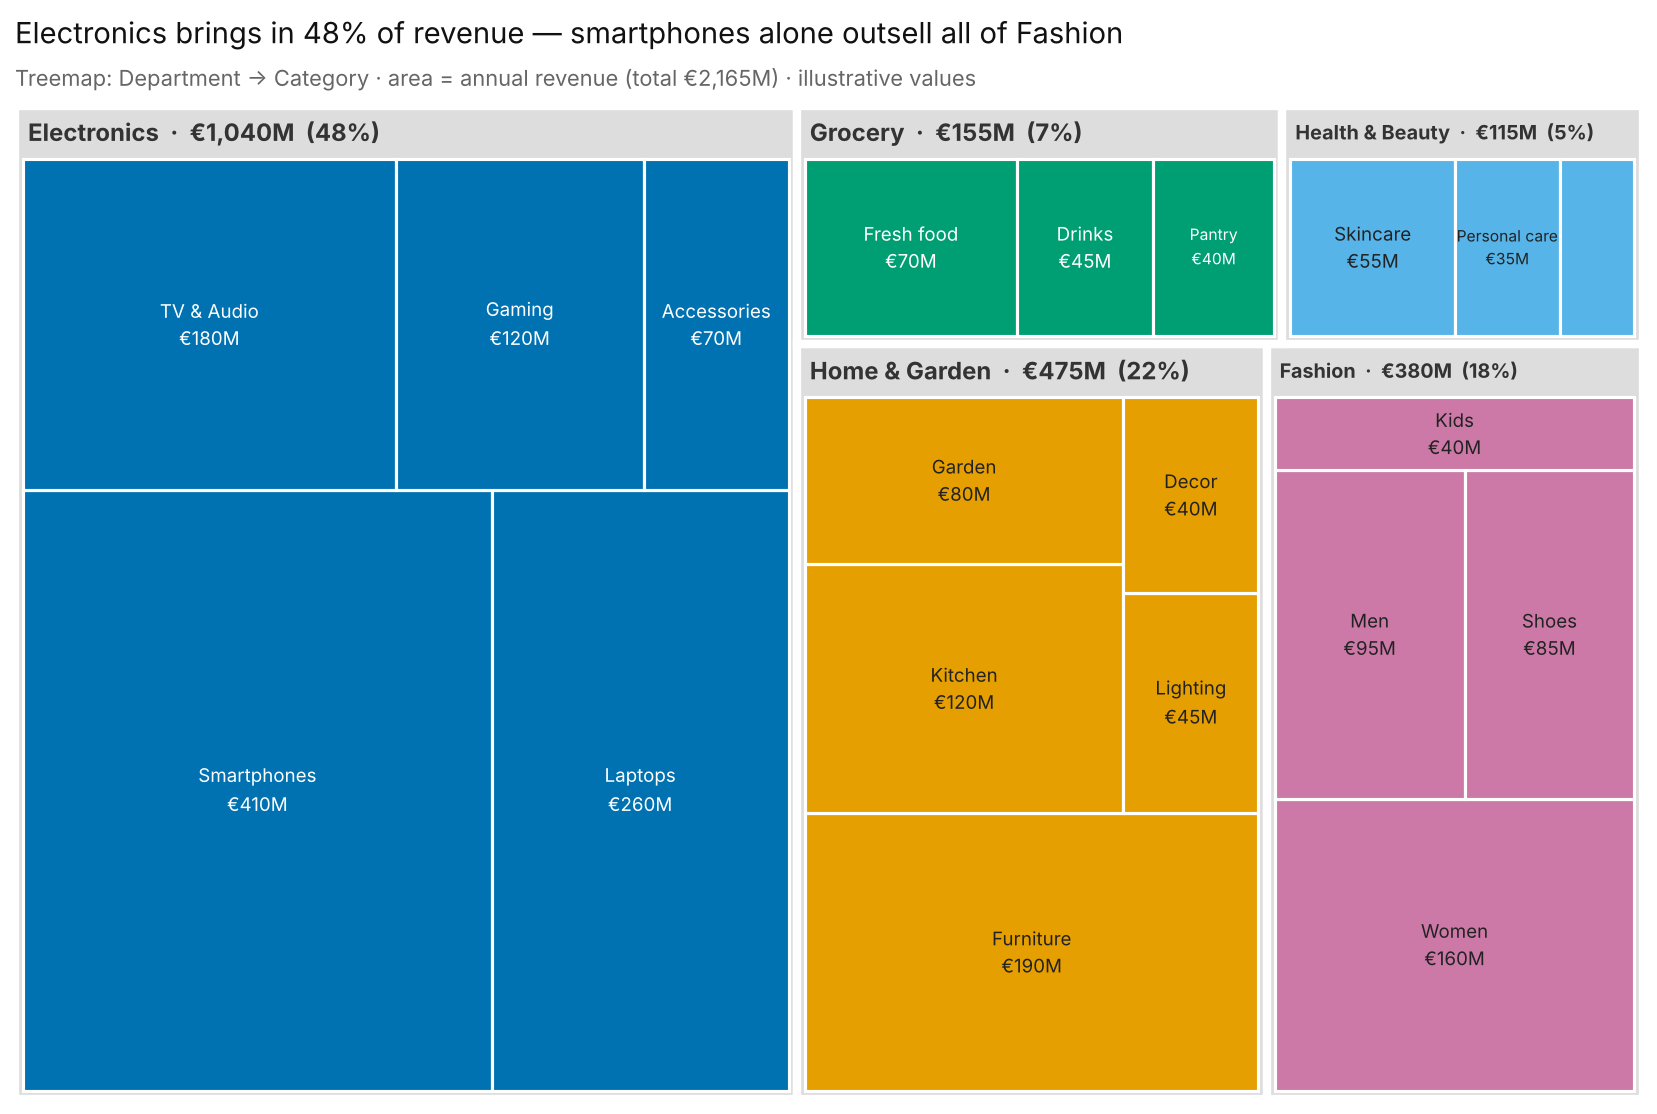 



---
## Let's Code Some Examples 💻 



In [1]:
import pandas as pd
import plotly.express as px
import numpy as np


# Dataset: Global Energy Mix by Country and Source

df = pd.read_csv('../data/global_energy_mix.csv')
print(f"Loaded: {len(df)} rows")
print(df.head(10))

Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh
0  United States  North America              Coal         10  1015.0
1  United States  North America               Oil         35  3220.0
2  United States  North America       Natural Gas         34  3083.0
3  United States  North America           Nuclear          9   798.0
4  United States  North America             Hydro          3   339.0
5  United States  North America              Wind          4   413.0
6  United States  North America             Solar          3   325.0
7  United States  North America  Other Renewables          2   229.0
8          China           Asia              Coal         58  6929.1
9          China           Asia               Oil         18  1620.0


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103 entries, 0 to 102
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Country    103 non-null    object 
 1   Region     103 non-null    object 
 2   Source     103 non-null    object 
 3   Share_pct  103 non-null    int64  
 4   TWh        103 non-null    float64
dtypes: float64(1), int64(1), object(3)
memory usage: 4.2+ KB


### Example 1 — Treemap: global energy mix

> 💡 **Examples 1 and 2 use the same data — energy by country and source type — visualised two ways.** Watch which question each chart answers easily, and which one it hides.

#### `px.treemap` — the arguments that matter

**Structure**
- `data_frame` — tidy table, one row per leaf (here: one row per country × source)
- `path` — list of columns from root to leaf, e.g. `['Region', 'Country', 'Source']`; the order *is* the hierarchy, and Plotly aggregates every parent level for you
- `values` — numeric column that sets rectangle **area**; must be additive (TWh, counts, sales) — never averages, rates or percentages, which do not sum to a meaningful parent


**Colour**
- `color` — a categorical column gives discrete colours, a numeric column gives a continuous scale
- `color_discrete_map` — dict that pins each category to a colour 
- `color_continuous_scale` (+ `range_color`, `color_continuous_midpoint`) — for numeric colour; use single-hue or diverging scales


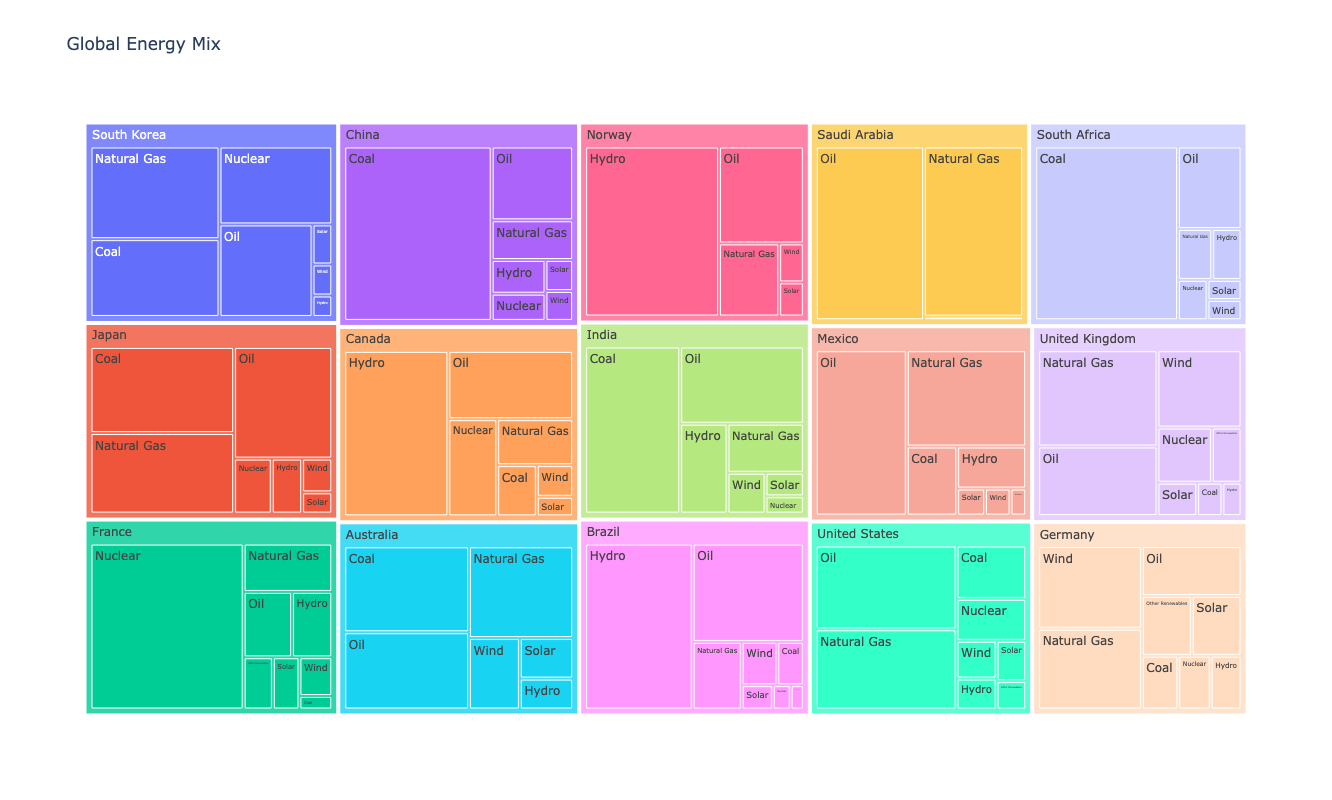

In [3]:
# exploratory figure

fig = px.treemap(df, path=['Country', 'Source'], values='TWh',
                 title='Global Energy Mix', height=800,
                 template='plotly_white')
fig.show()

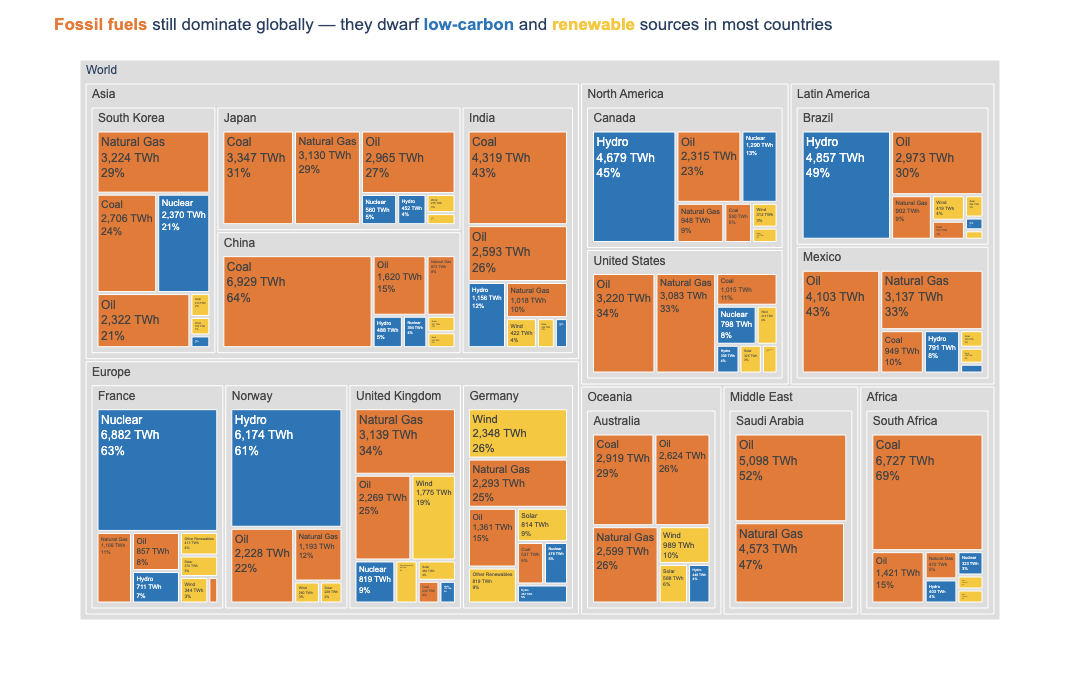

In [45]:
# Let's improve it

# Group sources into clean/dirty categories for colour
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

color_discrete_mapping = {
    'Fossil':     '#E07B39',   # orange: fossil fuels
    'Low-carbon': '#2E75B6',   # blue: nuclear + hydro
    'Renewable':  '#F5C842',   # yellow: wind, solar, other
}

# ── Step 1: Plotly Express base chart ─────────────────────────────────────────
fig = px.treemap(
    df,
    path=[px.Constant('World'), 'Region', 'Country', 'Source'],
    values='TWh',                      # use TWh — sums correctly at every level
    color='Source_Type',
    color_discrete_map=color_discrete_mapping,
    labels={'Source_Type': 'Energy type', 'TWh': 'Energy (TWh)'},
    height=700, width=1100,
    template='plotly_white'
)

# ── Step 2: Customisation ─────────────────────────────────────────────────────
fig.update_traces(
    # label, TWh and share of the parent (source → country, country → region, region → world)
    texttemplate='%{label}<br>%{value:,.0f} TWh<br>%{percentParent:.0%}',
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh<br>%{percentParent:.1%} of %{parent}<extra></extra>',
    root_color='white',
)

fig.update_layout(
    title=('<span style="color:#E07B39"><b>Fossil fuels</b></span> still dominate globally — they dwarf '
           '<span style="color:#2E75B6"><b>low-carbon</b></span> and '
           '<span style="color:#F5C842"><b>renewable</b></span> sources in most countries'),
    font=dict(family='Arial', size=12),
)

# Grey out parent nodes — replace any non-palette colour
fig.data[0].marker.colors = [
    c if c in color_discrete_mapping.values() else '#DDDDDD'
    for c in fig.data[0].marker.colors
]

fig.show()


### Example 2 — Stacked bars: the same data, a different question

> 💡 **Same data as the Example 1 treemap.**  100% stacked horizontal bars, one accent colour on the segment that matters, that segment placed on the baseline, direct labels instead of a legend, a left-aligned insight title and a footnote

In [7]:
df

,Country,Region,Source,Share_pct,TWh,Source_Type
0,United States,North America,Coal,10,1015.0,Fossil
1,United States,North America,Oil,35,3220.0,Fossil
2,United States,North America,Natural Gas,34,3083.0,Fossil
3,United States,North America,Nuclear,9,798.0,Low-carbon
4,United States,North America,Hydro,3,339.0,Low-carbon
...,...,...,...,...,...,...
98,Mexico,Latin America,Natural Gas,38,3137.0,Fossil
99,Mexico,Latin America,Nuclear,1,115.0,Low-carbon
100,Mexico,Latin America,Hydro,7,791.0,Low-carbon
101,Mexico,Latin America,Wind,2,188.0,Renewable


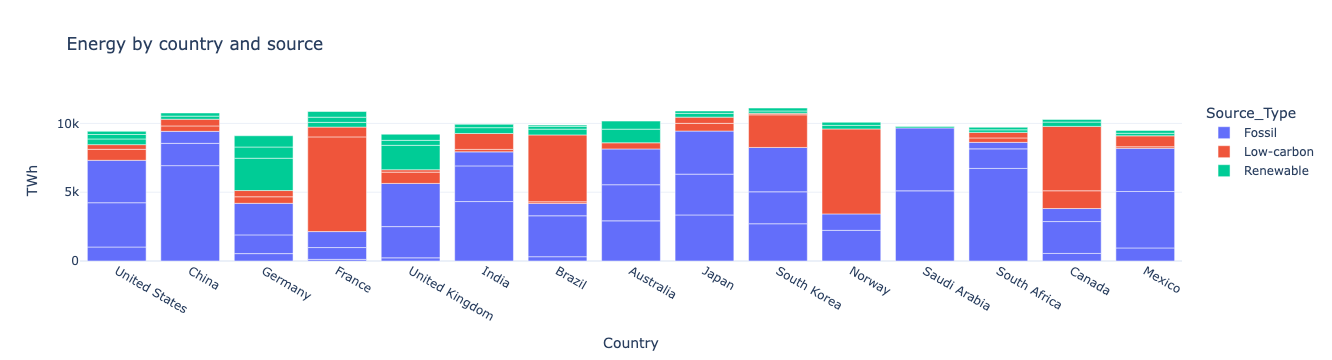

In [15]:
# exploratory — the default stacked bar: absolute TWh, 8 sources, 8 colours, alphabetical countries

fig = px.bar(df, x='Country', y='TWh', color='Source_Type', title='Energy by country and source',
             template='plotly_white')
fig.show()

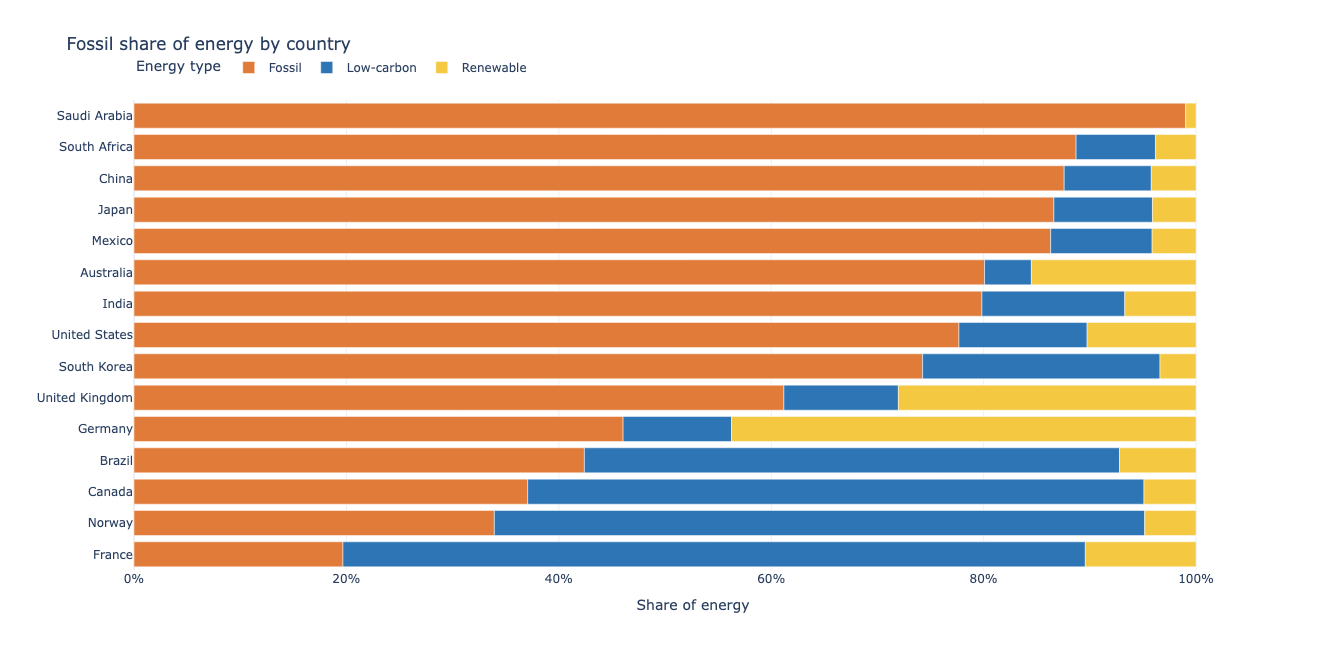

In [18]:
# Let's improve it — collapse to 3 source types, switch to shares, go horizontal, sort

# ── Data prep ─────────────────────────────────────────────────────────────────
mix = df.groupby(['Country', 'Source_Type'])['TWh'].sum().reset_index()
mix['Share'] = mix['TWh'] / mix.groupby('Country')['TWh'].transform('sum')   # 100% stacked → shares

# Sort countries by fossil share, most fossil-dependent at the top
country_order = (mix.loc[mix['Source_Type'] == 'Fossil']
                    .sort_values('Share', ascending=False)['Country'].tolist())

fig = px.bar(
    mix,
    x='Share', y='Country',
    color='Source_Type',                             
    color_discrete_map=color_discrete_mapping,   # same CVD-safe mapping as the treemap in Example 1
    category_orders={'Country': country_order,
                     'Source_Type': ['Fossil', 'Low-carbon', 'Renewable']},   # fossil sits on the baseline
    labels={'Share': 'Share of energy', 'Source_Type': 'Energy type'},
    title='Fossil share of energy by country',
    height=650,
    template='plotly_white',
)

fig.update_layout(xaxis=dict(tickformat='.0%'), yaxis=dict(title=''), legend=dict(orientation='h', x=0, y=1.1))

fig.show()

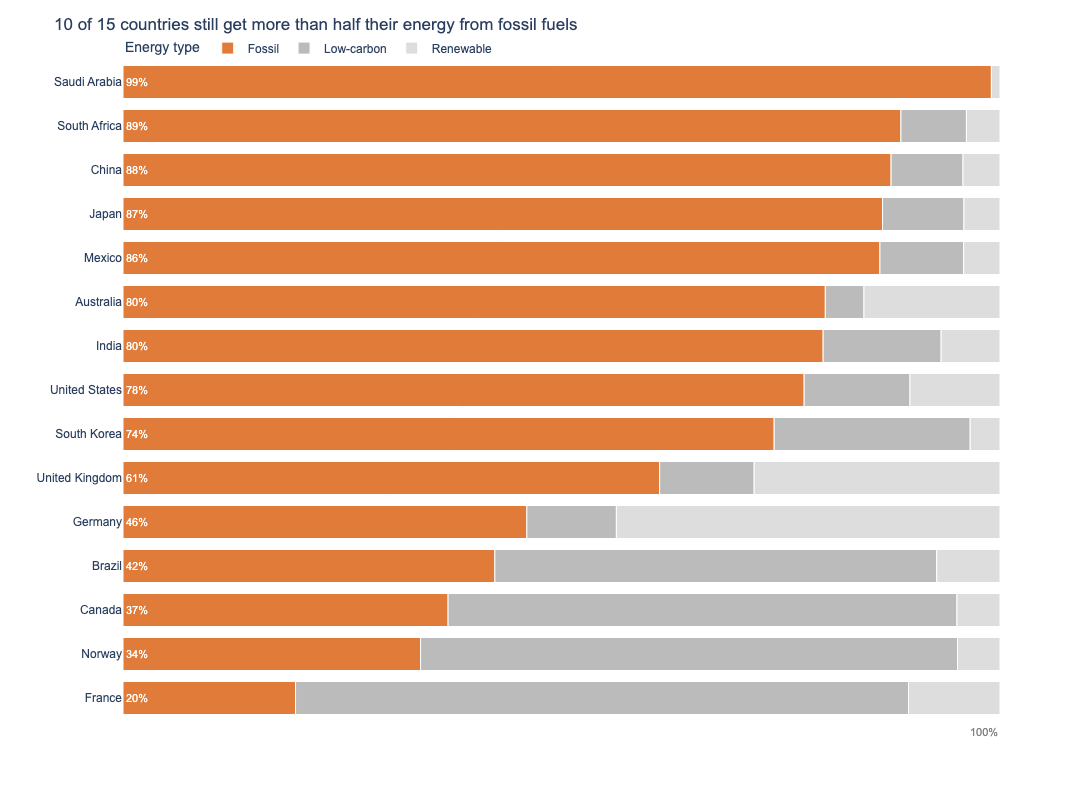

In [43]:
# Let's customise it — SWD model-visual style: grey + one accent, direct labels, insight title

# ── Data prep ─────────────────────────────────────────────────────────────────
majority_fossil = (mix.loc[mix['Source_Type'] == 'Fossil', 'Share'] > 0.5).sum()
n_countries = mix['Country'].nunique()

# Data labels only on the accent segment; empty text everywhere else
mix['Label'] = np.where(mix['Source_Type'] == 'Fossil', mix['Share'].map('{:.0%}'.format), '')

# One accent colour (orange = fossil, as in Example 1); two greys for context
accent_mapping = {
    'Fossil':     '#E07B39',   # orange accent — the story
    'Low-carbon': '#BBBBBB',   # mid grey — context
    'Renewable':  '#DDDDDD',   # light grey — context
}

# ── Step 1: Plotly Express base chart ─────────────────────────────────────────
fig = px.bar(
    data_frame=mix,
    x='Share', y='Country',
    color='Source_Type',
    text='Label',                                      # labels on fossil segments only
    color_discrete_map=accent_mapping,
    category_orders={'Country': country_order,
                     'Source_Type': ['Fossil', 'Low-carbon', 'Renewable']},
    labels={'Share': 'Share of energy', 'Source_Type': 'Energy type'},
    hover_name='Country',
    hover_data={'Label': False, 'Share':':.2f'},
    height=800, width=1000,
    template='plotly_white',
)

# ── Step 2: Customisation ─────────────────────────────────────────────────────
fig.update_traces(
    textposition='inside', insidetextanchor='start',   # label at the left edge of the segment
    textfont=dict(color='white', size=11),
    marker_line_color='white', marker_line_width=1,    # thin white separators between segments
)



fig.update_layout(
    title=dict(text=f'{majority_fossil} of {n_countries} countries still get more than half their energy from fossil fuels'),
    font=dict(family='Arial', size=12),
    bargap=0.25, 
    legend=dict(orientation='h', x=0, y=1.04),
    xaxis=dict(visible=False, range=[0, 1]),
    yaxis=dict(title=''))


# Mark the end of the scale — every bar sums to 100%, and the hidden x-axis no longer says so
fig.add_annotation(
    x=1, y=0,                      # x in data units (end of the bars), y at the bottom of the plot area
    xref='x', yref='paper',
    xanchor='right', yanchor='top',
    yshift=-4,                     # small gap below the last bar
    text='100%',
    showarrow=False,
    font=dict(size=11, color='grey'),
)



fig.show()

---
## Class Exercise 💻
